In [12]:
%matplotlib inline
import matplotlib.pyplot as plt
from pathlib import Path

if Path.cwd().name == "notebooks":
    %cd ..

In [13]:
%run src/drums/models/flow_matching.py

0: train=1.2358, test=1.2324
500: train=0.7211, test=0.6015
1000: train=0.5744, test=0.5525
1500: train=0.6524, test=0.5277
2000: train=0.5009, test=0.5100
2500: train=0.5083, test=0.5047
3000: train=0.4222, test=0.4799
3500: train=0.5122, test=0.4810
4000: train=0.4900, test=0.4691
4500: train=0.4228, test=0.4721


<Figure size 640x480 with 0 Axes>

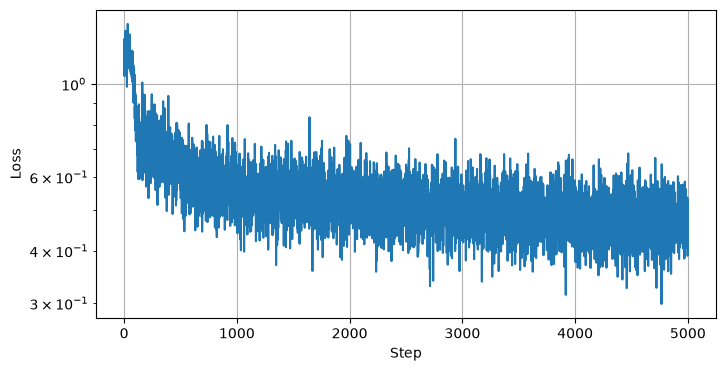

In [14]:
plt.figure(figsize=(8, 4))
plt.plot(history)
plt.xlabel("Step")
plt.ylabel("Loss")
plt.yscale("log")
plt.grid()
plt.show()

In [15]:
from itertools import permutations
import numpy as np
import jax
import jax.numpy as jnp
import jax.random as jr

orderings = jnp.array(list(permutations(range(3))))


def procrustes_error(target, prediction):
    target = target - target.mean(axis=0)

    def ordering_error(ordering):
        candidate = prediction[ordering]
        candidate = candidate - candidate.mean(axis=0)
        u, _, vt = jnp.linalg.svd(candidate.T @ target, full_matrices=False)
        aligned = candidate @ (u @ vt)
        return jnp.mean(
            jnp.linalg.norm(target - aligned, axis=1)
            / jnp.linalg.norm(target, axis=1)
        )

    return jnp.min(jax.vmap(ordering_error)(orderings))


batch_error = jax.jit(jax.vmap(procrustes_error))


def evaluate(model, spectra, vertices, n_draws=4, n_steps=100, seed=123):
    errors = []
    for draw_key in jr.split(jr.PRNGKey(seed), n_draws):
        keys = jr.split(draw_key, len(spectra))
        chunks = []
        for start in range(0, len(spectra), 128):
            stop = start + 128
            predictions = jax.vmap(
                lambda spectrum, key: sample(model, spectrum, key, n_steps=n_steps)
            )(spectra[start:stop], keys[start:stop])
            chunks.append(np.asarray(batch_error(vertices[start:stop], predictions)))
        errors.append(np.concatenate(chunks))
    return np.stack(errors)

In [16]:
assert spectra.shape == (1000, 30)
assert vertices.shape == (1000, 3, 2)
N_DRAWS, N_STEPS = 4, 100
errors17 = evaluate(model, spectra, vertices, n_draws=N_DRAWS, n_steps=N_STEPS)
print("Seed 17:", "train", errors17[:, :900].mean(), "test", errors17[:, 900:].mean())

Seed 17: train 0.1784606 test 0.1791117


In [17]:
model18, history18, spectra18, vertices18 = main(seed=18)
errors18 = evaluate(model18, spectra18, vertices18, n_draws=N_DRAWS, n_steps=N_STEPS)
print("Seed 18:", "train", errors18[:, :900].mean(), "test", errors18[:, 900:].mean())

0: train=1.1149, test=1.2285
500: train=0.6719, test=0.6324
1000: train=0.6152, test=0.5325
1500: train=0.5665, test=0.5161
2000: train=0.5319, test=0.5069
2500: train=0.5198, test=0.4926
3000: train=0.5013, test=0.4768
3500: train=0.4640, test=0.4525
4000: train=0.5958, test=0.4632
4500: train=0.5165, test=0.4552
Seed 18: train 0.17185171 test 0.17856155


In [18]:
# Baseline: log + standardise, AdamW, warmup + cosine, clipping, all orderings.
baseline = {17: (0.0054, 0.0058), 18: (0.0054, 0.0065)}
scores = []
print(f"All-orderings Procrustes error; FM averages {N_DRAWS} draws, {N_STEPS} Euler steps")
print("seed | FM train | FM test | baseline train | baseline test")
for seed, errors in [(17, errors17), (18, errors18)]:
    train_error, test_error = errors[:, :900].mean(), errors[:, 900:].mean()
    scores.append((train_error, test_error))
    b_train, b_test = baseline[seed]
    print(f"{seed:4d} | {train_error:.4f}   | {test_error:.4f}  | {b_train:.4f}         | {b_test:.4f}")
mean_train, mean_test = np.mean(scores, axis=0)
print(f"mean | {mean_train:.4f}   | {mean_test:.4f}  | 0.0054         | 0.0061")
print("Baseline means above are the rounded values reported in triangle_dataset_experiments.md.")
print("FM test std across sampling draws:",
      {seed: float(errors[:, 900:].mean(axis=1).std(ddof=1))
       for seed, errors in [(17, errors17), (18, errors18)]})

All-orderings Procrustes error; FM averages 4 draws, 100 Euler steps
seed | FM train | FM test | baseline train | baseline test
  17 | 0.1785   | 0.1791  | 0.0054         | 0.0058
  18 | 0.1719   | 0.1786  | 0.0054         | 0.0065
mean | 0.1752   | 0.1788  | 0.0054         | 0.0061
Baseline means above are the rounded values reported in triangle_dataset_experiments.md.
FM test std across sampling draws: {17: 0.008681225590407848, 18: 0.008702829480171204}
